# Adaptive LTV for tokenized real estate: a fuzzy closed-loop controller

**Author:** Christophe Abelem — Inteligência Computacional, CESUPA, 2026

## Generative AI disclosure

<!-- TODO (Christophe): fill before delivery. The lauda requires at least the four items below. -->
- **Tool:**
- **Purpose:**
- **Approximate extent of the contribution:**
- **Validation measures:**

## How to run

1. `uv venv --python 3.12 && source .venv/bin/activate`
2. `uv pip install -e ".[dev]"` installs the `adaptive_ltv` package and the notebook tools.
3. Run `00_data_test.ipynb` once: it downloads and freezes the data in `data/`.
4. `pytest` checks the package; then run this notebook top to bottom.

All computation lives in the `adaptive_ltv` package; this notebook calls it and explains the results.

## 1. Introduction and problem

**The setting.** Tokenized real estate splits a rental property into digital tokens. Each token gives its holder a
share of the rent. Holders can also deposit their tokens in a lending pool and borrow stablecoins (digital dollars)
against them, the way a home owner borrows against a house.

**The decision.** The pool must decide how much to lend per dollar of collateral. This ratio is the **maximum LTV**
(loan-to-value). With a max LTV of 60%, a token worth US$ 100 allows a loan of up to US$ 60. If the collateral loses
value and the loan rises above a second limit (the liquidation threshold), the position is **liquidated**: the
collateral is sold to repay the lenders. If the sale does not cover the debt, the shortfall is **bad debt**, a loss
for whoever lent the money.

**The problem.** A fixed max LTV ignores the state of the market. RealT, the largest tokenized real estate platform
(about 700 Detroit properties), used a fixed 60% in its lending market (RMM). In 2025-2026 rent stopped being
paid, the pool ran out of cash and liquidations surged; RealT announced its liquidation on 2 July 2026. Detroit house
prices, however, were near their all-time high. A rule that only watches prices would not have reacted.

**Objective.** Build a closed-loop fuzzy controller that sets the max LTV each month from three signals (price
volatility, pool liquidity, rent coverage) and compare its bad debt with the fixed 60% rule in two scenarios: a
market shock (prices fall, as in 2007-2011) and an operational collapse (rent and liquidity fail, as with RealT).

**Why fuzzy inference.** Risk teams set these limits with expert rules stated in words ("if volatility is high and
liquidity is low, lend less"). The boundaries are gradual, not sharp: 9% volatility is not "safe" while 9.1% is
"risky". Fuzzy sets model exactly this, and the rule base stays readable by someone outside finance.

**Sources and hypotheses.** Detroit prices: FRED `DEXRNSA`. Pool liquidity: DefiLlama. Risk parameters and
liquidations: read on-chain from the RMM contracts on Gnosis Chain. Rent coverage and appraisal steps are stylized
from documented dates (rent escrow Jul 2025, suspension Feb 2026), because no public time series exists. The data test
is in `00_data_test.ipynb`.

### Glossary

| Term | Meaning in this project |
| --- | --- |
| Collateral | The property tokens a borrower deposits to secure the loan |
| Max LTV | Largest loan allowed per dollar of collateral; the **output** of the controller |
| Liquidation threshold | Loan-to-value at which a position is liquidated (70% on RealT) |
| Liquidation | Forced sale of collateral to repay a loan that crossed the threshold |
| Bad debt | Debt left unpaid after a liquidation sale; the measure of failure |
| Volatility | How much prices swing; high volatility means collateral can lose value fast |
| Pool utilization | Share of the pool's cash already lent out; at 100% lenders cannot withdraw |
| Rent coverage | Share of expected rent actually paid; low coverage means the asset stopped producing income |
| Appraisal | Periodic official valuation of the property, used as the price the pool sees |

## Setup

In [ ]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from adaptive_ltv import environment as env
from adaptive_ltv.merton import expected_growth, log_return_variance, simulate_returns
from adaptive_ltv.scenarios import market_shock, merton_market_scenarios, operational_collapse
from adaptive_ltv.inputs import (CRUNCH_START, rent_coverage_stylized, utilization_daily,
                                 utilization_signal, volatility_signal)
from adaptive_ltv.analysis import REFERENCE, static_cases, surface
from adaptive_ltv.controller import FuzzyLTVController, build_rules
from adaptive_ltv.membership import (LTV_MAX, LTV_MIN, max_ltv_variable, rent_variable,
                                     utilization_variable, volatility_variable)
from adaptive_ltv.plots import LINE, SHADE, STYLE, pct_axis, plot_control_surface, plot_memberships

plt.rcParams.update(STYLE)

## 2. Input variables

### 2.1 Market volatility (Detroit house prices)

**What it measures.** How much Detroit house prices swing from month to month. High volatility means the collateral
(the property tokens) can lose value quickly, so a loan that is safe today may not be covered tomorrow.

**Source.** The S&P Cotality Case-Shiller index for Detroit (FRED series `DEXRNSA`): one number per month since
1991 that tracks the price of the same houses over time.

**Three corrections before using it:**

1. **Seasonality.** House prices rise every spring and fall every winter. That pattern is predictable, so it is
   not risk: each calendar month's average change is removed.
2. **Smoothing.** House price indices react slowly, because sale prices are agreed weeks before they are recorded:
   each month repeats part of the previous month's change. This hides how large the real swings are. The standard
   correction (Geltner) estimates how much of last month's change is repeated (the coefficient ρ, between 0 and 1)
   and removes it with the formula below.
3. **Rolling window.** Volatility is the standard deviation of the last 12 corrected monthly changes, scaled to a
   yearly figure (×√12). It is recomputed every month, which is what the controller reads.

Code: `adaptive_ltv/inputs.py` (`volatility_signal`).

```latex
r^{true}_t = \frac{r^{obs}_t - \rho \, r^{obs}_{t-1}}{1 - \rho}
```

In [ ]:
vol, info = volatility_signal()

print(f"AR(1) rho = {info['rho']:.3f}")
print(f"annualized vol, observed (SA): {info['vol_observed']:.1%}")
print(f"annualized vol, de-smoothed:   {info['vol_desmoothed']:.1%}")
print(f"rolling vol series: {vol.index.min():%Y-%m} to {vol.index.max():%Y-%m}, {len(vol)} months")

AR(1) rho = 0.725
annualized vol, observed (SA): 3.6%
annualized vol, de-smoothed:   9.1%
rolling vol series: 1992-02 to 2026-07, 414 months


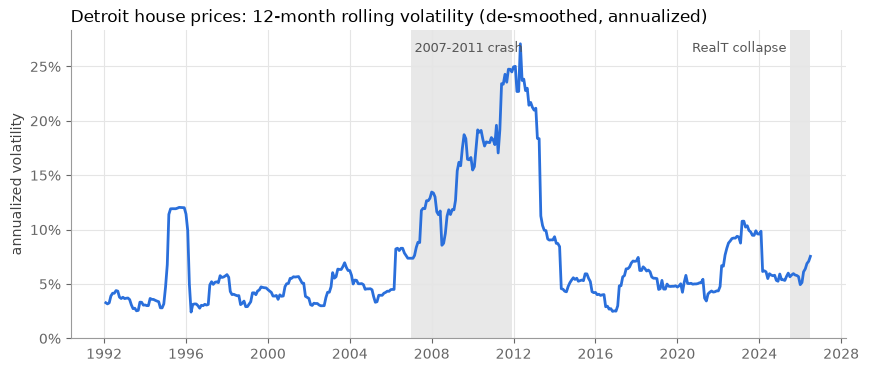

In [ ]:
fig, ax = plt.subplots()
for start, end in [("2007-01", "2011-12"), ("2025-07", "2026-07")]:
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color=SHADE, alpha=0.6, lw=0)
ax.plot(vol.index, vol, color=LINE, lw=2)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.set_ylim(0, None)
ax.set_title("Detroit house prices: 12-month rolling volatility (de-smoothed, annualized)", loc="left")
ax.set_ylabel("annualized volatility")
ax.text(pd.Timestamp("2007-03"), ax.get_ylim()[1] * 0.93, "2007-2011 crash", color="#555555", fontsize=9)
ax.text(pd.Timestamp("2025-05"), ax.get_ylim()[1] * 0.93, "RealT collapse", color="#555555", fontsize=9, ha="right")
plt.show()

In [ ]:
vol_pct = vol.quantile([0.10, 0.25, 0.50, 0.75, 0.90, 0.95])
print(pd.DataFrame({"percentile": [f"p{int(q * 100)}" for q in vol_pct.index],
                    "vol": vol_pct.map("{:.1%}".format).values}).to_string(index=False))
print("\nRealT period:")
print(vol.loc["2025-06":].map("{:.1%}".format).to_string())

percentile   vol
       p10  3.2%
       p25  4.2%
       p50  5.5%
       p75  9.1%
       p90 16.6%
       p95 20.1%

RealT period:
date
2025-06-01    6.0%
2025-07-01    5.7%
2025-08-01    5.8%
2025-09-01    6.0%
2025-10-01    5.8%
2025-11-01    5.8%
2025-12-01    5.7%
2026-01-01    4.9%
2026-02-01    5.1%
2026-03-01    6.1%
2026-04-01    6.4%
2026-05-01    6.9%
2026-06-01    7.1%
2026-07-01    7.5%


**Interpretation.**

- **De-smoothing matters.** Removing the smoothing (ρ = 0.73: each month repeats about 73% of the previous month's change) raises yearly volatility from 3.6% to 9.1%. The raw index hides most of the risk.
- **The 2007-2011 crash dominates the series,** with a peak of 27%. The peak came in May 2012, about a year after prices bottomed in April 2011: a 12-month rolling window only rises once the large drops are inside it, so the signal lags the price move. For the controller, this means volatility may cut the LTV late in a market shock, which the simulation must test.
- **During the RealT collapse (Jul 2025 to Jul 2026) volatility stayed between 4.9% and 7.5%,** close to the historical median of 5.5%. Detroit prices gave no warning, so a controller driven only by price risk would not have reacted. This supports the operational-collapse side of the hypothesis: the signal has to come from rent and pool liquidity.

### 2.2 Volatility as a fuzzy variable

**Universe:** 0% to 30% annualized volatility (the historical maximum is 27%).
**Terms:** low, medium, high, as trapezoids. The breakpoints are the historical percentiles of the series above, so no
number is chosen by hand:

| Term | Breakpoints | Reading |
| --- | --- | --- |
| low | 0, 0, p25, p50 | fully low up to p25, no longer low at the median |
| medium | p25, p50, p75, p90 | fully medium between the median and p75 |
| high | p75, p90, 30%, 30% | starts at p75, fully high from p90 |

Adjacent terms cross so that the memberships always sum to 1: every volatility value is covered, with no gaps.

Code: `adaptive_ltv/membership.py` (`volatility_variable`).

In [ ]:
VOL = volatility_variable(vol)

print("breakpoints:", {t: [f"{x:.1%}" for x in pts] for t, pts in VOL.terms.items()})
cov = VOL.coverage()
print(f"membership sum over the universe: min {cov.min():.3f}, max {cov.max():.3f}")

for label, x in [("median", vol.median()), ("RealT period, max", vol.loc["2025-07":].max()), ("2012 peak", vol.max())]:
    print(f"{label:>18} ({x:.1%}):", {t: round(d, 2) for t, d in VOL.memberships(x).items()})

breakpoints: {'low': ['0.0%', '0.0%', '4.2%', '5.5%'], 'medium': ['4.2%', '5.5%', '9.1%', '16.6%'], 'high': ['9.1%', '16.6%', '30.0%', '30.0%']}
membership sum over the universe: min 1.000, max 1.000
            median (5.5%): {'low': 0.03, 'medium': 0.97, 'high': 0.0}
 RealT period, max (7.5%): {'low': 0.0, 'medium': 1.0, 'high': 0.0}
         2012 peak (27.1%): {'low': 0.0, 'medium': 0.0, 'high': 1.0}


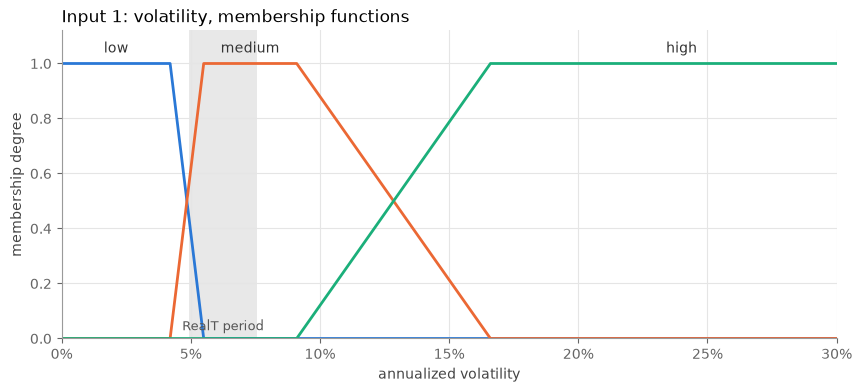

In [ ]:
realt = vol.loc["2025-07":]
plot_memberships(VOL, "Input 1: volatility, membership functions", "annualized volatility",
                 band=(realt.min(), realt.max()), band_label="RealT period", label_x={"high": 0.24})
plt.show()

**Reading.** The RealT period runs from 4.9% (about half "low", half "medium") to 7.5% (fully "medium"). The 2012 peak is fully
"high". Volatility alone would therefore keep the max LTV near its normal level during the RealT collapse.

### 2.3 Pool utilization

**What it measures.** The share of the pool's money already lent out: borrowed / (borrowed + idle cash). The pool holds stablecoins, digital tokens worth US$ 1 each that work as digital dollars.
At 100% the pool has no idle cash, so lenders cannot withdraw and new loans cannot be funded. Source: DefiLlama,
daily, averaged per month because the controller decides monthly. Code: `adaptive_ltv/inputs.py` (`utilization_signal`).

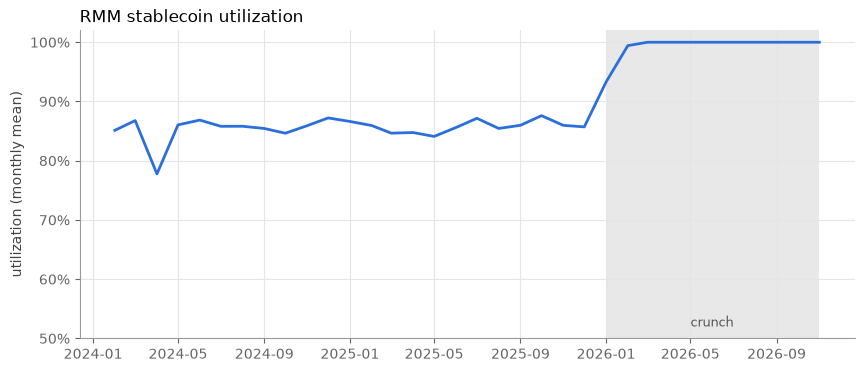

date
2025-06-01     85.6%
2025-07-01     87.2%
2025-08-01     85.4%
2025-09-01     86.0%
2025-10-01     87.6%
2025-11-01     86.0%
2025-12-01     85.7%
2026-01-01     93.3%
2026-02-01     99.4%
2026-03-01    100.0%
Freq: MS


In [ ]:
util_d = utilization_daily()
util = utilization_signal()

fig, ax = plt.subplots()
ax.axvspan(pd.Timestamp(CRUNCH_START), util.index.max(), color=SHADE, alpha=0.6, lw=0)
ax.text(pd.Timestamp("2026-06-01"), 0.52, "crunch", ha="center", color="#555555", fontsize=9)
ax.plot(util.index, util, color=LINE, lw=2)
pct_axis(ax.yaxis)
ax.set_ylim(0.5, 1.02)
ax.set_ylabel("utilization (monthly mean)")
ax.set_title("RMM stablecoin utilization", loc="left")
plt.show()

print(util.loc["2025-06":"2026-03"].map("{:.1%}".format).to_string())

**Reading.** Utilization stayed between 84% and 87% for almost two years (one dip to 78% in April 2024), then jumped to 93% in January 2026 and
to 99-100% from February: the pool emptied in two months and never recovered. Utilization therefore moves
*with* the crunch, not before it; it is a coincident signal, not an early warning.

**Fuzzy terms.** The normal range is too narrow (84% to 88%) for percentile-based terms, so the breakpoints follow
observed behaviour:

| Term | Breakpoints | Reading |
| --- | --- | --- |
| healthy | 0, 0, median, 90% | fully healthy up to the pre-crunch median (85.8%) |
| tight | median, 90%, 95%, 99% | 90% is above every month before the crunch (max 87.6%) |
| crunch | 95%, 99%, 100%, 100% | the pool has practically no idle cash |

breakpoints: {'healthy': ['0.0%', '0.0%', '85.8%', '90.0%'], 'tight': ['85.8%', '90.0%', '95.0%', '99.0%'], 'crunch': ['95.0%', '99.0%', '100.0%', '100.0%']}
membership sum over the universe: min 1.000, max 1.000
2025-12 (85.7%): {'healthy': 1.0, 'tight': 0.0, 'crunch': 0.0}
2026-01 (93.3%): {'healthy': 0.0, 'tight': 1.0, 'crunch': 0.0}
2026-02 (99.4%): {'healthy': 0.0, 'tight': 0.0, 'crunch': 1.0}


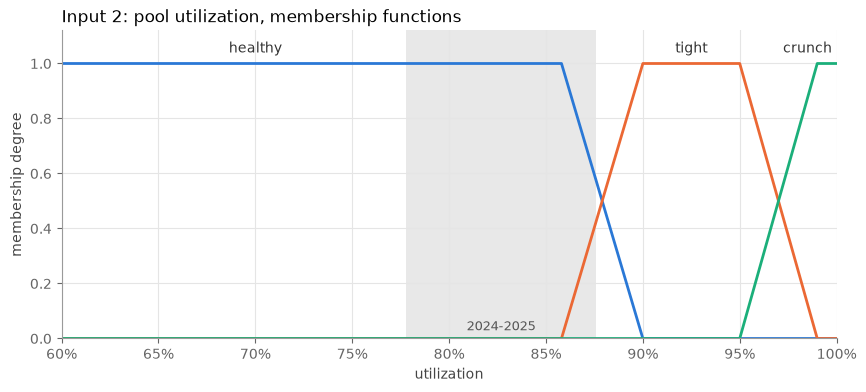

In [ ]:
UTIL = utilization_variable(util_d)
print("breakpoints:", {t: [f"{x:.1%}" for x in pts] for t, pts in UTIL.terms.items()})
print(f"membership sum over the universe: min {UTIL.coverage().min():.3f}, max {UTIL.coverage().max():.3f}")
for d in ["2025-12-01", "2026-01-01", "2026-02-01"]:
    print(f"{d[:7]} ({util[d]:.1%}):", {t: round(x, 2) for t, x in UTIL.memberships(util[d]).items()})

plot_memberships(UTIL, "Input 2: pool utilization, membership functions", "utilization",
                 band=(util.loc[:"2025-12"].min(), util.loc[:"2025-12"].max()), band_label="2024-2025",
                 label_x={"healthy": 0.70, "crunch": 0.985}, xlim=(0.6, 1.0))
plt.show()

### 2.4 Rent coverage (stylized)

**What it measures.** The share of the expected rent actually paid to token holders: 100% means rent arrives as
promised, 0% means the property produces no income.

**Why stylized.** RealT's public API went offline after the liquidation and no rent time series is published. The
series is built from documented dates: rent escrow from July 2025, distributions largely halted by the end of
2025, formal suspension in February 2026 (Outlier Media, BridgeDetroit, Lofty). The path between those dates is an
assumption: linear fall from 100% in June 2025 to 20% in December 2025, 10% in January 2026, zero after.
**Limitation:** because the timing of the fall is set by the scenario, the project shows how the controller reacts
to falling rent; it cannot prove that rent fell before the pool emptied. Code: `rent_coverage_stylized`.

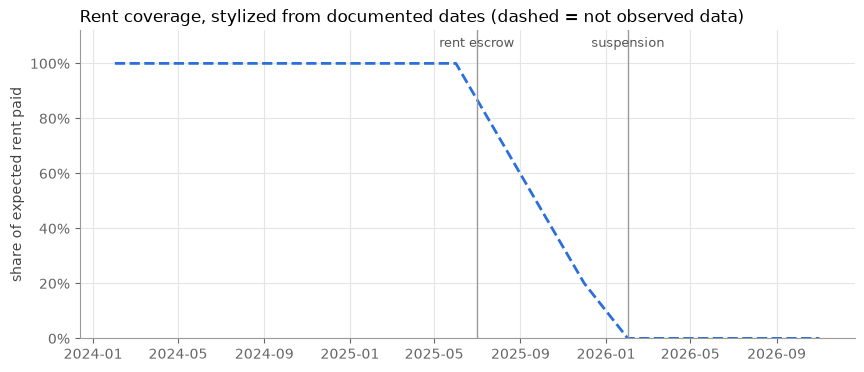

In [ ]:
rent = rent_coverage_stylized()

fig, ax = plt.subplots()
ax.plot(rent.index, rent, color=LINE, lw=2, ls="--")
for d, label in [("2025-07-01", "rent escrow"), ("2026-02-01", "suspension")]:
    ax.axvline(pd.Timestamp(d), color="#9a9a9a", lw=1)
    ax.text(pd.Timestamp(d), 1.06, label, ha="center", color="#555555", fontsize=9)
pct_axis(ax.yaxis)
ax.set_ylim(0, 1.12)
ax.set_ylabel("share of expected rent paid")
ax.set_title("Rent coverage, stylized from documented dates (dashed = not observed data)", loc="left")
plt.show()

**Fuzzy terms.** With no historical distribution to anchor them, the breakpoints are stated hypotheses:

| Term | Breakpoints | Reading |
| --- | --- | --- |
| low | 0, 0, 30%, 60% | below 30% the asset is not producing income |
| partial | 30%, 60%, 80%, 95% | a partial payer |
| full | 80%, 95%, 100%, 100% | from 95% rent is paid as expected |

membership sum over the universe: min 1.000, max 1.000
2025-08 (73%): {'low': 0.0, 'partial': 1.0, 'full': 0.0}
2025-10 (47%): {'low': 0.44, 'partial': 0.56, 'full': 0.0}
2025-12 (20%): {'low': 1.0, 'partial': 0.0, 'full': 0.0}


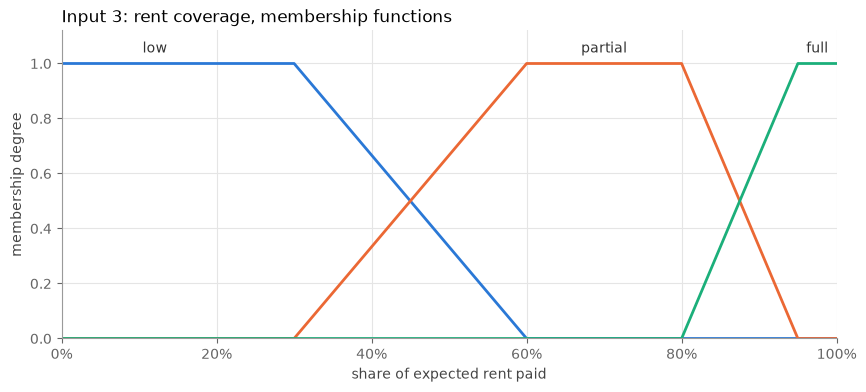

In [ ]:
RENT = rent_variable()
print(f"membership sum over the universe: min {RENT.coverage().min():.3f}, max {RENT.coverage().max():.3f}")
for d in ["2025-08-01", "2025-10-01", "2025-12-01"]:
    print(f"{d[:7]} ({rent[d]:.0%}):", {t: round(x, 2) for t, x in RENT.memberships(rent[d]).items()})

plot_memberships(RENT, "Input 3: rent coverage, membership functions", "share of expected rent paid",
                 label_x={"low": 0.12, "full": 0.975})
plt.show()

### 2.5 Output: max LTV

**What it is.** The largest loan the pool allows per dollar of collateral, set by the controller every month,
between 30% (crisis) and 60% (RealT's fixed value, the benchmark).

**Terms.** Triangles centred on 30% (low), 45% (medium) and 60% (high), each 15 points wide on either side. The
universe runs from 15% to 75% so that, when a single term is active, the centroid (the centre of mass of the output shape, the standard way to turn a fuzzy result back into one number) lands exactly on the term's centre: a calm
market gives exactly 60%, the same as the fixed rule, which keeps the comparison fair. The crisp output is then
clipped to [30%, 60%]. Code: `max_ltv_variable`.

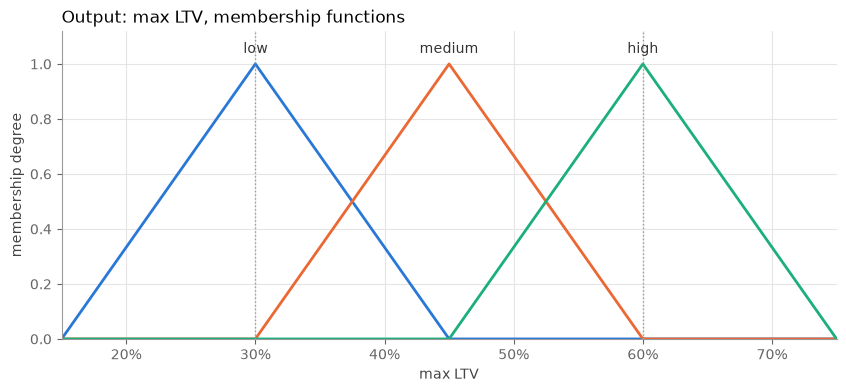

In [ ]:
LTV = max_ltv_variable()
fig, ax = plot_memberships(LTV, "Output: max LTV, membership functions", "max LTV")
for x in (LTV_MIN, LTV_MAX):
    ax.axvline(x, color="#9a9a9a", lw=1, ls=":")
plt.show()

## 3. Rule base

**The principle.** Each input term gets a severity score: how much it worsens the risk of lending. The rule for each
combination adds the three scores and maps the total to an output term. This keeps the 27 rules consistent with one
idea instead of 27 separate judgements.

| Input | Term → severity | Why |
| --- | --- | --- |
| Volatility | low 0 · medium 1 · high 2 | medium is the normal market (it contains the median), so it scores little |
| Utilization | healthy 0 · tight 2 · crunch 4 | an empty pool means lenders cannot withdraw: severe on its own |
| Rent coverage | full 0 · partial 2 · low 4 | an asset that stopped paying rent is a severe signal on its own |

| Total severity | Output term | Max LTV |
| --- | --- | --- |
| 0 to 1 | high | 60% (same as RealT's fixed rule) |
| 2 to 3 | medium | 45% |
| 4 or more | low | 30% |

**Consequences of the principle.** A calm market (medium volatility, healthy pool, full rent) scores 1 and keeps
the 60% of the fixed rule. High volatility alone scores 2: the LTV drops to 45%. A crunch or failed rent scores
4 on its own: the LTV drops to 30% whatever the volatility, because a calm price does not offset an empty pool or an
asset that stopped paying.

The tables below list all 27 rules, one table per rent level (rows: volatility; columns: utilization). Code:
`adaptive_ltv/controller.py` (`build_rules`).

In [ ]:
rules = pd.DataFrame(build_rules(), columns=["volatility", "utilization", "rent_coverage", "max_ltv"])
print(f"{len(rules)} rules, {rules[['volatility', 'utilization', 'rent_coverage']].drop_duplicates().shape[0]} distinct input combinations")
for r in ["full", "partial", "low"]:
    t = (rules[rules.rent_coverage == r]
         .pivot(index="volatility", columns="utilization", values="max_ltv")
         .loc[["low", "medium", "high"], ["healthy", "tight", "crunch"]])
    print(f"\nRent coverage = {r}")
    print(t.to_string())

27 rules, 27 distinct input combinations

Rent coverage = full
utilization healthy   tight crunch
volatility                        
low            high  medium    low
medium         high  medium    low
high         medium     low    low

Rent coverage = partial
utilization healthy tight crunch
volatility                      
low          medium   low    low
medium       medium   low    low
high            low   low    low

Rent coverage = low
utilization healthy tight crunch
volatility                      
low             low   low    low
medium          low   low    low
high            low   low    low


**Coherence check.** Making any single input worse never raises the max LTV. This is tested in
`tests/test_controller.py` over a grid of inputs. One known effect of Mamdani inference appears there: where two
output terms overlap, the centroid can move up by a fraction of a point (measured maximum: 0.3 point of LTV). The
test allows 0.5 point for that effect.

### 3.1 How the controller decides (Mamdani inference)

For every month the controller runs four steps. The example below uses October 2025, when RealT's rent was already
failing but the pool still had cash.

1. **Fuzzification:** each input number becomes degrees of membership in its terms.
2. **Rule activation:** each rule is active to the degree of its weakest condition (the minimum of its three degrees).
3. **Aggregation:** each active rule cuts its output term at its activation level; the cut shapes are overlaid
   (maximum), giving one combined shape over the LTV axis.
4. **Defuzzification:** the centroid of that shape is the max LTV, kept between 30% and 60%.

Inputs 2025-10: volatility 5.8%, utilization 87.6%, rent coverage 47%
      volatility: {'medium': 1.0}
     utilization: {'healthy': 0.57, 'tight': 0.43}
   rent_coverage: {'low': 0.44, 'partial': 0.56}
Active rules:
  IF volatility is medium AND utilization is healthy AND rent is partial THEN max LTV is medium   (strength 0.56)
  IF volatility is medium AND utilization is healthy AND rent is low THEN max LTV is low   (strength 0.44)
  IF volatility is medium AND utilization is tight AND rent is partial THEN max LTV is low   (strength 0.43)
  IF volatility is medium AND utilization is tight AND rent is low THEN max LTV is low   (strength 0.43)
Max LTV = 38.2%


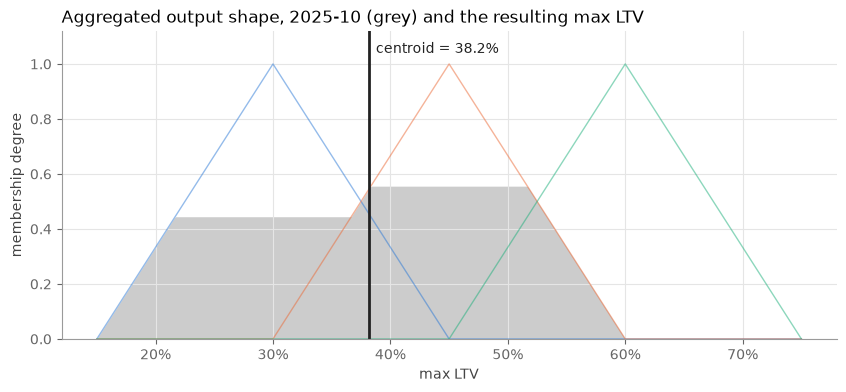

In [ ]:
CTRL = FuzzyLTVController(VOL, UTIL, RENT, LTV)

month = "2025-10-01"
d = CTRL.decide(vol[month], util[month], rent[month])
print(f"Inputs {month[:7]}: volatility {vol[month]:.1%}, utilization {util[month]:.1%}, rent coverage {rent[month]:.0%}")
for name, degrees in d.memberships.items():
    print(f"  {name:>14}:", {t: round(x, 2) for t, x in degrees.items() if x > 0})
print("Active rules:")
for (v, u, r, out), s in sorted(d.activations, key=lambda a: -a[1]):
    if s > 0:
        print(f"  IF volatility is {v} AND utilization is {u} AND rent is {r} THEN max LTV is {out}   (strength {s:.2f})")
print(f"Max LTV = {d.max_ltv:.1%}")

fig, ax = plt.subplots()
for (term, mf), color in zip(LTV.mf.items(), ["#2a78d6", "#eb6834", "#1baf7a"]):
    ax.plot(LTV.universe, mf, color=color, lw=1, alpha=0.5)
ax.fill_between(LTV.universe, d.aggregated, color="#9a9a9a", alpha=0.5, lw=0)
ax.axvline(d.max_ltv, color="#222222", lw=2)
ax.text(d.max_ltv + 0.006, 1.04, f"centroid = {d.max_ltv:.1%}", ha="left", fontsize=10, color="#222222")
pct_axis(ax.xaxis)
ax.set_ylim(0, 1.12)
ax.set_xlabel("max LTV")
ax.set_ylabel("membership degree")
ax.set_title(f"Aggregated output shape, {month[:7]} (grey) and the resulting max LTV", loc="left")
plt.show()

### 3.2 Preview: the controller on the real RealT period (no feedback yet)

Before building the market simulation, the controller can be applied to the observed signals of 2024-2026 month by
month. This is **open loop**: the decisions do not change the market here. The closed loop comes in sections 5 and 6.

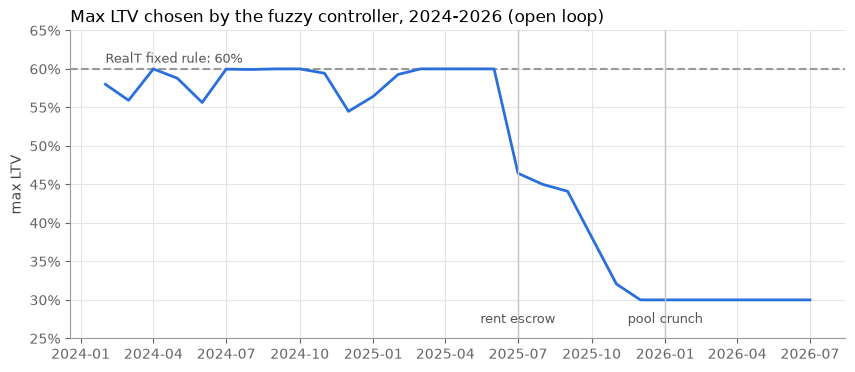

             vol utilization rent_coverage max_ltv
2025-05-01  5.7%       84.1%          100%   60.0%
2025-06-01  6.0%       85.6%          100%   60.0%
2025-07-01  5.7%       87.2%           87%   46.4%
2025-08-01  5.8%       85.4%           73%   45.0%
2025-09-01  6.0%       86.0%           60%   44.1%
2025-10-01  5.8%       87.6%           47%   38.2%
2025-11-01  5.8%       86.0%           33%   32.1%
2025-12-01  5.7%       85.7%           20%   30.0%
2026-01-01  4.9%       93.3%           10%   30.0%
2026-02-01  5.1%       99.4%            0%   30.0%


In [ ]:
signals = pd.concat([vol, util, rent], axis=1).dropna()
signals["max_ltv"] = [CTRL(*row) for row in signals[["vol", "utilization", "rent_coverage"]].values]

fig, ax = plt.subplots()
ax.axhline(LTV_MAX, color="#9a9a9a", lw=1.5, ls="--")
ax.text(signals.index.min(), LTV_MAX + 0.008, "RealT fixed rule: 60%", color="#555555", fontsize=9)
ax.plot(signals.index, signals["max_ltv"], color=LINE, lw=2)
for dte, label in [("2025-07-01", "rent escrow"), ("2026-01-01", "pool crunch")]:
    ax.axvline(pd.Timestamp(dte), color="#c4c4c4", lw=1)
    ax.text(pd.Timestamp(dte), 0.27, label, ha="center", fontsize=9, color="#555555")
pct_axis(ax.yaxis)
ax.set_ylim(0.25, 0.65)
ax.set_ylabel("max LTV")
ax.set_title("Max LTV chosen by the fuzzy controller, 2024-2026 (open loop)", loc="left")
plt.show()

print(signals.loc["2025-05":"2026-02"].assign(
    vol=lambda df: df.vol.map("{:.1%}".format), utilization=lambda df: df.utilization.map("{:.1%}".format),
    rent_coverage=lambda df: df.rent_coverage.map("{:.0%}".format), max_ltv=lambda df: df.max_ltv.map("{:.1%}".format)
).to_string())

**Reading.** In 2024 the limit dips to 55-58% in a few months: utilization rose slightly above its median (85.8%),
which makes it partly "tight". From March 2025 the controller keeps 60% until June 2025, then cuts the limit as rent
falls: 46% in July, 38% in
October, 30% from December 2025, one month before the pool ran out of cash in January 2026. Volatility stayed
"medium" throughout and played no part.

**Caution.** The early cut comes from the rent series, which is stylized: its timing was set from documented dates,
not measured. What this preview shows is how the rules react to falling rent, not that rent data would have given
this warning in practice. In the 2007-2011 crash, by contrast, only volatility reacts: it lowers the limit to 45% at
most, and only after prices had already been falling for about a year (section 2.1). Both points are tested in the
simulations.

## 4. Static tests and control surfaces

Before the controller runs inside a simulation, it is tested on fixed inputs: does it give sensible limits in
typical situations, at the extremes, and in the zones where one term turns into another? Code:
`adaptive_ltv/analysis.py`.

### 4.1 Test cases

In [ ]:
cases = {
    "calm market":              dict(volatility=0.055, utilization=0.85, rent_coverage=1.00),
    "very calm market":         dict(volatility=0.030, utilization=0.75, rent_coverage=1.00),
    "market shock":             dict(volatility=0.200, utilization=0.85, rent_coverage=1.00),
    "pool crunch":              dict(volatility=0.055, utilization=0.995, rent_coverage=1.00),
    "rent failure":             dict(volatility=0.055, utilization=0.85, rent_coverage=0.10),
    "everything bad":           dict(volatility=0.250, utilization=1.00, rent_coverage=0.00),
    "transition: volatility":   dict(volatility=0.129, utilization=0.85, rent_coverage=1.00),
    "transition: utilization":  dict(volatility=0.055, utilization=0.88, rent_coverage=1.00),
    "transition: rent":         dict(volatility=0.055, utilization=0.85, rent_coverage=0.45),
}
table = static_cases(CTRL, cases)
print(table.assign(
    volatility=table.volatility.map("{:.1%}".format), utilization=table.utilization.map("{:.1%}".format),
    rent_coverage=table.rent_coverage.map("{:.0%}".format), max_ltv=table.max_ltv.map("{:.1%}".format),
).to_string())

                        volatility utilization rent_coverage max_ltv  active_rules                        strongest_rule
case                                                                                                                    
calm market                   5.5%       85.0%          100%   60.0%             1       medium / healthy / full -> high
very calm market              3.0%       75.0%          100%   60.0%             1          low / healthy / full -> high
market shock                 20.0%       85.0%          100%   45.0%             1       high / healthy / full -> medium
pool crunch                   5.5%       99.5%          100%   30.0%             1         medium / crunch / full -> low
rent failure                  5.5%       85.0%           10%   30.0%             1         medium / healthy / low -> low
everything bad               25.0%      100.0%            0%   30.0%             1            high / crunch / low -> low
transition: volatility       12.

**Reading.**

- **Typical case.** A calm market keeps exactly 60%, the same limit as RealT's fixed rule: the controller only
  departs from the benchmark when a signal says so.
- **Extremes.** A market shock alone lowers the limit to 45%; a pool crunch alone or a rent failure alone lower it
  to 30%, the minimum. This is the intended asymmetry: price swings are tolerated more than an empty pool or an asset
  that stopped paying.
- **Transitions.** Values on the border between two terms activate two rules at once and give intermediate limits
  (52% at 12.9% volatility, 37.5% at 45% rent), so the limit changes gradually instead of jumping.

### 4.2 Control surfaces

Each surface shows the max LTV (height) over two inputs, with the third input fixed at a normal value: volatility
5.5% (the median), utilization 85% (healthy) or rent coverage 100% (full). Lighter and lower means a tighter limit.

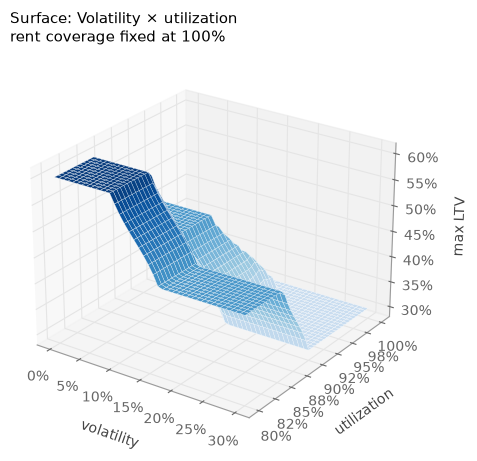

Volatility × utilization: limit at the 30% floor in 27% of the grid, at 60% in 9%


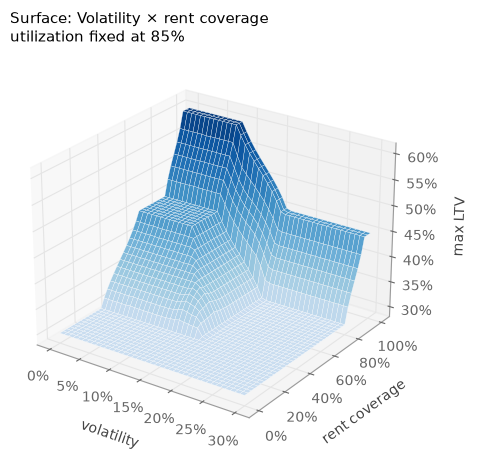

Volatility × rent coverage: limit at the 30% floor in 53% of the grid, at 60% in 2%


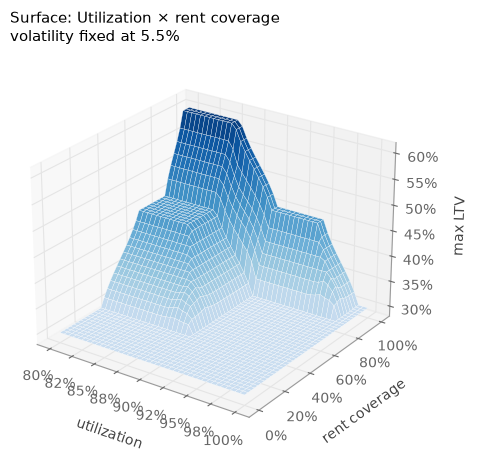

Utilization × rent coverage: limit at the 30% floor in 58% of the grid, at 60% in 2%


In [ ]:
pairs = [("volatility", "utilization", "Volatility × utilization"),
         ("volatility", "rent_coverage", "Volatility × rent coverage"),
         ("utilization", "rent_coverage", "Utilization × rent coverage")]
fixed_label = {"volatility": "volatility fixed at {:.1%}", "utilization": "utilization fixed at {:.0%}",
               "rent_coverage": "rent coverage fixed at {:.0%}"}
surfaces = {}
for x_name, y_name, title in pairs:
    xs, ys, z, (third, value) = surface(CTRL, x_name, y_name, n=41)
    surfaces[(x_name, y_name)] = z
    plot_control_surface(xs, ys, z, x_name.replace("_", " "), y_name.replace("_", " "),
                         f"Surface: {title}", fixed_label[third].format(value))
    plt.show()
    print(f"{title}: limit at the 30% floor in {(z < 0.301).mean():.0%} of the grid, at 60% in {(z > 0.599).mean():.0%}")

**Analysis of the surfaces.**

- **Influence of each input.** All three inputs move the limit. Volatility has the gentlest effect: on its own it
  only brings the limit down to 45%, and only above about 9% (the start of "high"). Utilization acts late but
  strongly: nothing happens below 86%, then the limit falls to 30% between 95% and 99%, whatever the volatility. Rent coverage acts across
  most of its range: the limit starts falling as soon as coverage drops below 95%.
- **Transitions.** The slopes sit exactly where adjacent terms overlap (for example 86% to 90% utilization, 30% to
  60% rent coverage). Outside those zones the surface is flat, because a single rule is active.
- **Unexpected results.** (0) The first version of the rules scored a crunch and failed rent at 3. The first
  surface then showed that very low volatility (below 4.2%) raised the limit back to 45% during a crunch: a calm price
  was offsetting an empty pool. Both scores were raised to 4, so either signal alone now sets the 30% floor whatever
  the volatility (a test in `tests/test_controller.py` keeps it that way). (1) Large flat areas at the 30% floor: about half of the volatility × rent and utilization ×
  rent grids. Once two signals are bad the controller has nothing lower to offer; this is a deliberate floor, but it
  means the controller cannot tell "bad" from "very bad". (2) Small bumps where the limit rises by up to 0.3 point
  when an input gets worse, the Mamdani centroid effect noted in section 3.
- **Limitations.** The surfaces show one pair at a time around a normal month; they do not show combinations where
  all three inputs are stressed. The rent breakpoints are hypotheses (section 2.4), so the shape of every surface
  along the rent axis depends on them.

## 5. The market environment (closed-loop model)

To test the controller, the lending pool is simulated month by month. Each month the controller looks at the
current state, sets the max LTV, and the environment computes the next state:
`next_state = update_market(state, max_ltv)`. The next state is what the controller reads the following month.
Code: `adaptive_ltv/environment.py`.

**What the state contains.** 200 borrowers, each with one unit of property tokens as collateral and a loan; the
money deposited by lenders (the pool's supply); the prices of the collateral; and the three controller inputs.

**The prices of the collateral.** This is the central point of the RealT case:

| Price | What it is | Role |
| --- | --- | --- |
| House value | Detroit house prices (de-smoothed index, data) | what the property is worth |
| Appraisal (oracle) | official valuation, updated only every 12 months | the price the pool uses to check loans and trigger liquidations |
| Token value | the house value minus a discount when rent stops | what a token is worth to a buyer |
| Market price | the token value minus the selling pressure of forced sales that month | what a liquidation actually gets |

When rent stops, the token value falls while the appraisal stays high: the pool believes loans are safe while the
collateral can no longer cover them. Losses appear when the gap is finally exposed.

**One month, in six steps:**

1. **Borrowers react to the limit.** They borrow up to their usual share of the allowed amount; if the limit has
   fallen below what they owe, they repay part of the excess (10% a month). This also happens under the fixed rule, when a new appraisal
   lowers the allowed amount.
2. **Interest.** Borrowers pay interest out of the rent their tokens earn; when rent stops, unpaid interest is added
   to the debt. The interest rate rises steeply when the pool is almost empty (above 90% utilization).
3. **Lenders.** While rent is paid, deposits and withdrawals balance. When rent coverage falls to 10% or less,
   lenders run: they try to withdraw 17% of the money a month, but can only take the idle cash. (Calibrated on the
   real pool, section 5.2.)
4. **Prices.** The house value follows the data; the appraisal is refreshed every 12 months; the token value
   follows the house value and the rent.
5. **Liquidations.** A loan above 70% of the appraisal (RealT's threshold) is closed: the collateral is sold at the
   market price. If the sale does not cover the debt, the shortfall is bad debt, a loss for the lenders.
6. **Volatility.** The volatility of the market price over the last 12 months is recomputed.

**The feedback loop.** Two of the controller's three inputs depend on its own past decisions:
- **utilization**: the max LTV decides how much is borrowed, which sets the share of the pool lent out;
- **volatility**: the max LTV decides how many loans reach the liquidation threshold; forced sales push the market
  price down, which raises the volatility.

Rent coverage follows the scenario. In the operational collapse the token's market price falls *because* rent
falls, so the volatility input partly repeats the rent signal; section 6.1 (c) checks that the result barely changes
when the controller reads the data volatility instead. When there are no forced sales and rent is paid, the simulated volatility is
exactly the data volatility of section 2.1 (tested in `tests/test_environment.py`).

**Assumptions.** Prices, volatility and rent come from the data and the scenarios; lender flows are calibrated on
the real pool; the rest of the behaviour has no public data and is stated here, then tested in section 6.1:

In [ ]:
print(pd.DataFrame([{"assumption": k, "value": str(v[0]), "meaning": v[1]} for k, v in env.ASSUMPTIONS.items()]).to_string(index=False))
print(f"\nFixed from the RealT contracts: start max LTV {env.START_LTV:.0%}, liquidation threshold {env.LIQ_THRESHOLD:.0%}, liquidation bonus {env.LIQ_BONUS:.0%}")

         assumption             value                                                                                                                                                                                                                                                                                                   meaning
        n_borrowers               200                                                                                                                                                                                                                                            number of borrower positions, each with one unit of collateral
       target_share        (0.5, 1.0)                                                                                                                                                                                                                                each borrower borrows a fixed share of the allowed amount, drawn un

### 5.1 The two scenarios

| Scenario | Period | What happens |
| --- | --- | --- |
| Market shock | Detroit, Jan 2006 to Dec 2012 | house prices fall by about half; rent keeps being paid |
| Operational collapse | RealT, Feb 2024 to Jul 2026 | house prices stay near their peak; rent stops (stylized path); lenders run |

/Users/christopheabelempinho/Documents/adaptive-ltv-rwa/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 6.
  fig.canvas.print_figure(bytes_io, **kw)


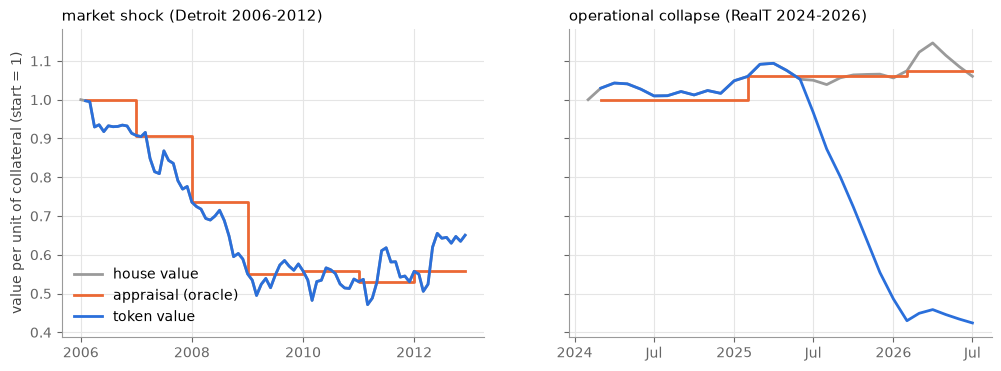

In [ ]:
SCENARIOS = [market_shock(), operational_collapse()]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, sc in zip(axes, SCENARIOS):
    res = env.run(sc, env.fixed_policy())
    ax.plot(sc.house_index.index, sc.house_index, color="#9a9a9a", lw=2, label="house value")
    ax.plot(res.index, res["oracle_price"], color="#eb6834", lw=2, drawstyle="steps-post", label="appraisal (oracle)")
    ax.plot(res.index, res["token_value"], color=LINE, lw=2, label="token value")
    ax.set_title(sc.name, loc="left", fontsize=11)
    loc = mdates.AutoDateLocator(maxticks=6)
    ax.xaxis.set_major_locator(loc)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))
axes[0].set_ylabel("value per unit of collateral (start = 1)")
axes[0].legend(frameon=False, loc="lower left")
plt.show()

**Reading.** In the market shock the three prices fall together (the token value line covers the house value line):
the appraisal lags by up to a year, but the token keeps its value relative to the house. In the operational collapse
the house value even rises while the token value falls by about 60%: the appraisal never shows it.

### 5.2 Model check: simulated vs real pool

The real RMM pool is the check. The simulation runs the operational-collapse scenario under RealT's actual rule
(fixed 60%), so its utilization can be compared with the real one (DefiLlama).

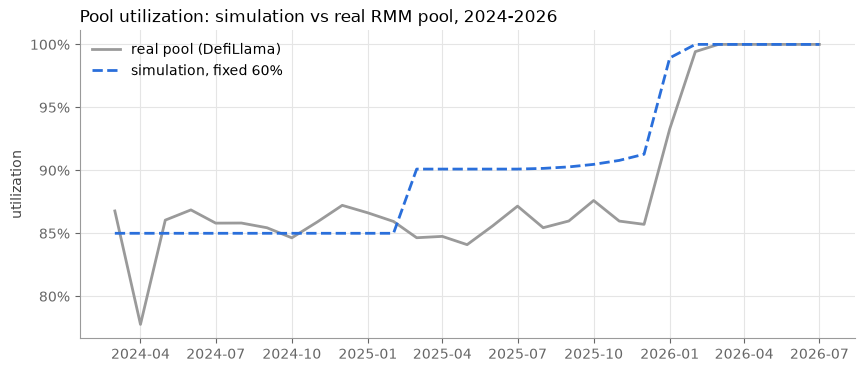

mean absolute gap: 2.5%; before 2026: 3.0%; from 2026: 0.9%


In [ ]:
check = env.run(SCENARIOS[1], env.fixed_policy())
real_util = util.reindex(check.index)
fig, ax = plt.subplots()
ax.plot(real_util.index, real_util, color="#9a9a9a", lw=2, label="real pool (DefiLlama)")
ax.plot(check.index, check["utilization"], color=LINE, lw=2, ls="--", label="simulation, fixed 60%")
pct_axis(ax.yaxis)
ax.set_ylabel("utilization")
ax.set_title("Pool utilization: simulation vs real RMM pool, 2024-2026", loc="left")
ax.legend(frameon=False)
plt.show()
gap = (check["utilization"] - real_util).dropna()
print(f"mean absolute gap: {gap.abs().mean():.1%}; before 2026: {gap.loc[:'2025-12'].abs().mean():.1%}; from 2026: {gap.loc['2026-01':].abs().mean():.1%}")

**Reading.** The simulation reproduces the shape of the real pool: stable for almost two years, then emptied within
two months in January-February 2026, and stuck at 100% afterwards. Before the crunch the simulated level is a few
points higher than the real one (about 90% against 85-87%), because simulated borrowers borrow more when the
appraisal is raised in early 2025. **This check is only partly independent:** the moment the lenders run was calibrated on the same dates as the
stylized rent, so the timing of the January 2026 jump is built in. The independent part is the level before the
crunch, which the model gets within a few points. The model is a simplification, but it is not detached from what
happened.

## 6. Closed-loop results: fixed rule vs fuzzy controller

Both policies start from the same loan book (built under RealT's 60%) and face the same scenario. The measure of
failure is the **total loss**: bad debt from liquidations plus debt the collateral cannot cover at the end, as a
percentage of the money lenders had deposited at the start.

In [ ]:
POLICIES = [("fixed 60%", env.fixed_policy()), ("fuzzy", CTRL)]
results, rows = {}, []
for sc in SCENARIOS:
    for name, policy in POLICIES:
        res = env.run(sc, policy)
        results[(sc.name, name)] = res
        rows.append({"scenario": sc.name, "policy": name, **env.loss_summary(res)})
print(pd.DataFrame(rows).set_index(["scenario", "policy"]).round(1).to_string())

                                                  liquidations  realized_bad_debt_%  uncovered_debt_at_end_%  total_loss_%  lowest_max_ltv_%
scenario                               policy                                                                                               
market shock (Detroit 2006-2012)       fixed 60%           151                  2.8                      0.0           2.8              60.0
                                       fuzzy                54                  0.0                      0.0           0.0              45.0
operational collapse (RealT 2024-2026) fixed 60%            63                 22.7                     23.1          45.8              60.0
                                       fuzzy                 0                  0.0                      5.6           5.6              30.0


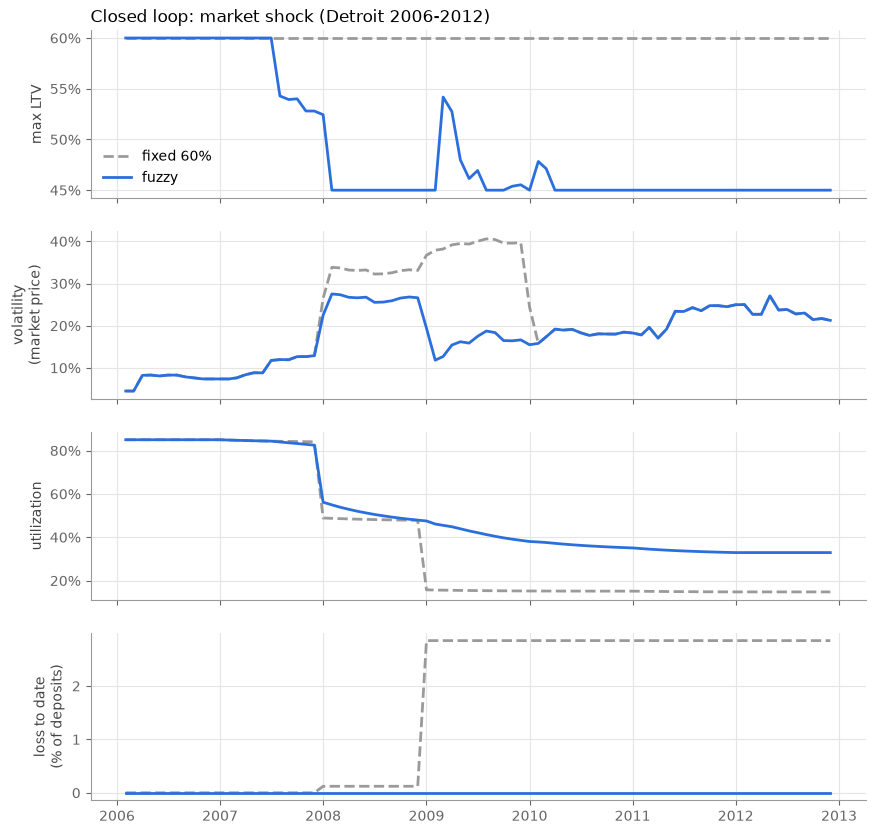

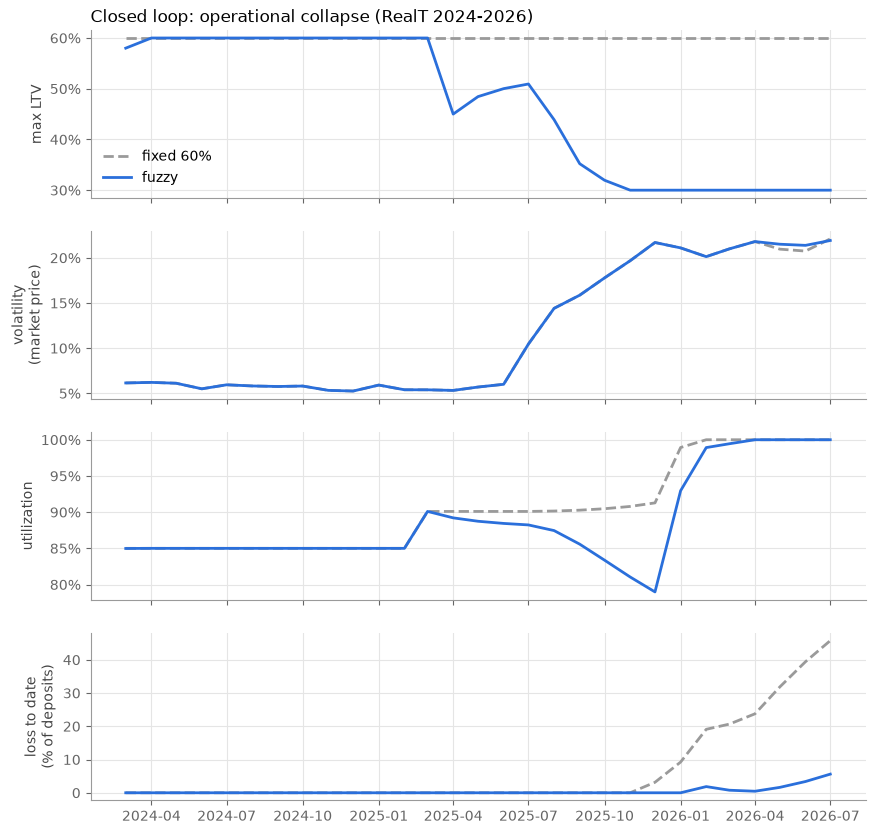

In [ ]:
for sc in SCENARIOS:
    fig, axes = plt.subplots(4, 1, figsize=(10, 10), sharex=True)
    for name, color, ls in [("fixed 60%", "#9a9a9a", "--"), ("fuzzy", LINE, "-")]:
        r = results[(sc.name, name)]
        axes[0].plot(r.index, r["max_ltv"], color=color, ls=ls, lw=2, label=name)
        axes[1].plot(r.index, r["volatility"], color=color, ls=ls, lw=2)
        axes[2].plot(r.index, r["utilization"], color=color, ls=ls, lw=2)
        axes[3].plot(r.index, 100 * r["loss_to_date"] / r.attrs["initial_supply"], color=color, ls=ls, lw=2)
    axes[0].set_ylabel("max LTV"); pct_axis(axes[0].yaxis); axes[0].legend(frameon=False)
    axes[1].set_ylabel("volatility\n(market price)"); pct_axis(axes[1].yaxis)
    axes[2].set_ylabel("utilization"); pct_axis(axes[2].yaxis)
    axes[3].set_ylabel("loss to date\n(% of deposits)")
    axes[0].set_title(f"Closed loop: {sc.name}", loc="left")
    plt.show()

### 6.1 How much do the results depend on the assumptions?

Three checks: (a) 20 different random borrower books (seeds); (b) how fast borrowers repay when the limit falls;
(c) the other assumptions without public data, one at a time, plus a controller that reads the data volatility
instead of the simulated one.

In [ ]:
seed_rows = []
for sc in SCENARIOS:
    for name, policy in POLICIES:
        losses = [env.loss_summary(env.run(sc, policy, seed=k))["total_loss_%"] for k in range(20)]
        seed_rows.append({"scenario": sc.name, "policy": name, "mean_loss_%": np.mean(losses),
                          "min_%": np.min(losses), "max_%": np.max(losses)})
print("(a) 20 seeds")
print(pd.DataFrame(seed_rows).set_index(["scenario", "policy"]).round(1).to_string())

sens_rows = []
for rate in [0.0, 0.05, 0.10, 0.15, 0.20]:
    with env.assumption("deleverage_rate", rate):
        for sc in SCENARIOS:
            for name, policy in POLICIES:
                sens_rows.append({"repaid per month": f"{rate:.0%}", "scenario": sc.name, "policy": name,
                                  "total_loss_%": env.loss_summary(env.run(sc, policy))["total_loss_%"]})
print("\n(b) share of the excess borrowers repay each month when the limit falls")
print(pd.DataFrame(sens_rows).pivot_table(index=["scenario", "policy"], columns="repaid per month",
                                          values="total_loss_%", sort=False).round(1).to_string())

(a) 20 seeds
                                                  mean_loss_%  min_%  max_%
scenario                               policy                              
market shock (Detroit 2006-2012)       fixed 60%          3.7    2.0    5.9
                                       fuzzy              0.0    0.0    0.0
operational collapse (RealT 2024-2026) fixed 60%         44.5   43.0   46.5
                                       fuzzy              5.7    5.4    6.0

(b) share of the excess borrowers repay each month when the limit falls
repaid per month                                    0%    5%   10%   15%   20%
scenario                               policy                                 
market shock (Detroit 2006-2012)       fixed 60%   4.9   3.6   2.8   2.5   2.4
                                       fuzzy       4.9   0.0   0.0  13.9  13.0
operational collapse (RealT 2024-2026) fixed 60%  47.0  46.5  45.8  45.4  45.5
                                       fuzzy      47.0  22.4   

In [ ]:
def data_vol_policy(policy, scenario):
    """The same policy, but reading the data volatility of the scenario instead of the simulated one."""
    month = {"t": 0}
    def wrapped(volatility, utilization, rent_coverage):
        v = scenario.volatility.iloc[month["t"]]
        month["t"] += 1
        return policy(volatility if np.isnan(v) else v, utilization, rent_coverage)
    return wrapped

checks = [("baseline", None, None)]
checks += [(f"price impact {v}", "price_impact", v) for v in (0.0, 0.25, 0.75)]
checks += [(f"appraisal every {v} months", "appraisal_months", v) for v in (6, 24)]
checks += [(f"token discount without rent {v:.0%}", "token_discount", v) for v in (0.4, 0.8)]
robust_rows = []
for label, key, value in checks:
    for sc in SCENARIOS:
        for name, policy in POLICIES:
            if key is None:
                loss = env.loss_summary(env.run(sc, policy))["total_loss_%"]
            else:
                with env.assumption(key, value):
                    loss = env.loss_summary(env.run(sc, policy))["total_loss_%"]
            robust_rows.append({"check": label, "scenario": sc.name, "policy": name, "loss": loss})
for sc in SCENARIOS:
    for name, policy in POLICIES:
        robust_rows.append({"check": "controller reads data volatility", "scenario": sc.name, "policy": name,
                            "loss": env.loss_summary(env.run(sc, data_vol_policy(policy, sc)))["total_loss_%"]})
robust = pd.DataFrame(robust_rows)
robust["column"] = robust["scenario"].str.split(" ").str[0] + ": " + robust["policy"]
print("(c) total loss, % of deposits")
print(robust.pivot_table(index="check", columns="column", values="loss", sort=False).round(1).to_string())

(c) total loss, % of deposits
column                            market: fixed 60%  market: fuzzy  operational: fixed 60%  operational: fuzzy
check                                                                                                         
baseline                                        2.8            0.0                    45.8                 5.6
price impact 0.0                                0.0            0.0                    44.5                 5.6
price impact 0.25                               0.1            0.0                    45.1                 5.6
price impact 0.75                               9.9            0.0                    46.4                 5.6
appraisal every 6 months                        2.5            9.6                    45.7                 5.7
appraisal every 24 months                       2.8            0.2                    39.7                 5.3
token discount without rent 40%                 2.8            0.0                

### 6.2 Many possible futures: Merton jump-diffusion

The market shock above is one history. To see how the two rules behave over many possible futures, house prices are
simulated with a **Merton jump-diffusion**: each month the price moves by a normal amount plus, occasionally, a jump
(a sudden large move). The parameters are estimated from the de-smoothed Detroit returns 1992-2026: months more than
3 robust standard deviations from the median count as jumps, the rest as normal moves. Code: `adaptive_ltv/merton.py`.

**Validation.** The model has closed-form answers for the expected price growth and the variance of returns. The
simulation must reproduce them before it is used.

In [ ]:
params, paths = merton_market_scenarios(n_paths=300, months=84, seed=0)
print(params.as_table().round(4).to_string(index=False))

sims = simulate_returns(params, months=84, n_paths=200_000, seed=11)
mc_growth, cf_growth = np.exp(sims.sum(axis=1)).mean(), expected_growth(params, 84)
mc_var, cf_var = sims.sum(axis=1).var(), log_return_variance(params, 84)
print(f"\nExpected 7-year growth: Monte Carlo {mc_growth:.4f} vs closed form {cf_growth:.4f} (gap {mc_growth / cf_growth - 1:+.2%})")
print(f"Variance of 7-year log return: Monte Carlo {mc_var:.4f} vs closed form {cf_var:.4f} (gap {mc_var / cf_var - 1:+.2%})")

                    parameter   value
           mu (monthly drift)  0.0034
sigma (monthly diffusion vol)  0.0156
      lambda (jumps per year)  0.8753
                    mean jump -0.0065
                     jump std  0.0812

Expected 7-year growth: Monte Carlo 1.3205 vs closed form 1.3190 (gap +0.11%)
Variance of 7-year log return: Monte Carlo 0.0612 vs closed form 0.0612 (gap -0.03%)


In [ ]:
mc_rows = []
for name, policy in POLICIES:
    losses = np.array([env.loss_summary(env.run(sc, policy))["total_loss_%"] for sc in paths])
    mc_rows.append({"policy": name, "mean_loss_%": losses.mean(), "95th_percentile_%": np.percentile(losses, 95),
                    "99th_percentile_%": np.percentile(losses, 99), "worst_%": losses.max(),
                    "share_of_futures_with_loss_>1%": (losses > 1).mean()})
print(f"{len(paths)} simulated 7-year futures, rent paid throughout")
print(pd.DataFrame(mc_rows).set_index("policy").round(2).to_string())

300 simulated 7-year futures, rent paid throughout
           mean_loss_%  95th_percentile_%  99th_percentile_%  worst_%  share_of_futures_with_loss_>1%
policy                                                                                               
fixed 60%         0.05                0.0               1.46     4.88                            0.02
fuzzy             0.00                0.0               0.00     0.01                            0.00


**Reading.**

- **Operational collapse: a robust result.** The controller cuts the loss from about 46% to about 6% of deposits
  (20 seeds: 44.5% against 5.7%). It stays at about 5-6% when the price impact, the appraisal frequency or the
  volatility input change (table c). As rent falls the controller reaches 30% by late 2025, borrowers shrink their
  loans, and when the pool empties in January 2026 the remaining loans are small. Under the fixed 60% the loans stay
  large, unpaid interest and the empty pool push them over the threshold, and the collateral is sold far below its
  appraisal. The *size* of the gain depends on how much a token loses when rent stops: with a 40% discount, 13% against
  0%; with 80%, 83% against 44%. The direction does not change.
- **The condition behind it.** Lowering the limit only helps if borrowers actually reduce existing loans. With no
  repayment (0%), both rules give the same loss: a lower limit on new loans alone changes nothing. More repayment
  always helps in this scenario (47% → 22% → 6% → 0%).
- **Market shock: no robust conclusion.** Losses are small under both rules, and the comparison changes sign with the
  assumptions. In the baseline the controller avoids a 2.8% loss: the first forced sales of 2008 push the market price
  down, the volatility it reads jumps, and it cuts the limit before the 2009 appraisal. But with no price impact
  neither rule loses anything; with an appraisal every 6 months the controller is worse (9.6% against 2.5%); with
  faster repayment (15-20% a month) it is worse too (13-14% against 2-3%), because no loan is liquidated early, the
  volatility does not rise, and 149 loans are then liquidated together and sold at a deep discount. With an appraisal
  that moves in steps, losses depend on whether liquidations arrive spread out or all at once, and the controller can
  make that better or worse.
- **Over 300 random futures (Merton), price risk alone rarely costs anything.** The fixed rule loses more than 1% of
  deposits in 2% of the futures (worst case 4.9%), the fuzzy rule in none. These losses also come from the price
  impact of forced sales, so the same caution applies. The simulation reproduces the model's closed-form growth and
  variance within 0.2%.
- **What this does not show.** The rent path is stylized, so the timing of the controller's reaction in the
  operational collapse comes from the scenario, not from measured data. Repayment behaviour, the token discount
  without rent and the price impact of forced sales have no public data; table (c) and table (b) show how much they
  matter. The model check (section 5.2) is only partly independent.
